# Unterrichtsbeispiel

[&larr; Einführung](01_SCIPY.ipynb)

## Motivation

Anhand einer Beispielaufgabe wollen wir wichtige Operationen der Signalverarbeitung bzw. numerischen Mathematik kennenlernen.

---

## Aufgabe

An rotierenden Maschinen (z. B. Kreiselpumpen) treten Schwingungen/Vibrationen auf, die gewisse Grenzwerte nicht überschreiten dürfen. Pumpenschwingungen können verschiedene Ursachen haben und können auf bestimmte Schadensbilder hindeuten. Aus diesem Grund ist die Schwingungsanalyse äusserst nützlich, um bestimmte Mängel bzw. Schäden zu erkennen bzw. zukünftige Schäden vermeiden zu können.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/pump-with-sensors-render.png" width="60%">
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Vibrationsmessung an einer Kreiselpumpe <a href="https://www.ifm.com/in/en/shared/technologies/real-time-maintenance/centrifugal-pump">[Quelle]</a>
    </figcaption>
</figure>

Anhand einer Messung der Vibrationen am Pumpengehäuse mit einem Beschleunigungssensor soll untersucht werden, ob der in der Norm definierte Grenzwert der Schwingstärke eingehalten wird.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/ISO10816-Bild-3.jpg" width=60%/>
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Grenzwerte für die Pumpenschwingungen gemäss DIN ISO 10816 <a href="https://adm-messtechnik.de/anwendung-maschinenschwingungen/">[Quelle]</a>
    </figcaption>
</figure>


---

### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, integrate

Vorab-Übung: Importieren der Betriebspunkt-Daten aus der Datei `Pump_OperatingPoint.txt` und grafische Darstellung.

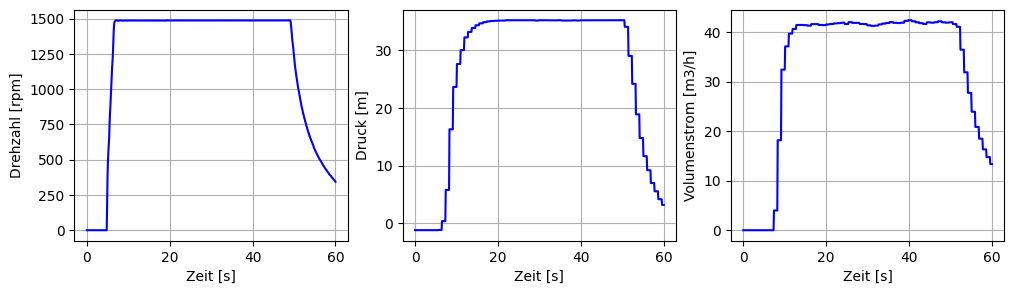

In [3]:
data = np.loadtxt('data/Pump_OperatingPoint.txt', skiprows=1)
t = data[:,0]
n = data[:,1]
p = data[:,2]
V_dot = data[:,3]

fig, axs = plt.subplots(ncols=3, figsize=(12, 3))
axs[0].plot(t, n, 'b')
axs[0].set_xlabel('Zeit [s]')
axs[0].set_ylabel('Drehzahl [rpm]')
axs[0].grid()
axs[1].plot(t, p, 'b')
axs[1].set_xlabel('Zeit [s]')
axs[1].set_ylabel('Druck [m]')
axs[1].grid()
axs[2].plot(t, V_dot, 'b')
axs[2].set_xlabel('Zeit [s]')
axs[2].set_ylabel('Volumenstrom [m3/h]')
axs[2].grid()
plt.show()

### a) Datensatz einlesen und Überblick verschaffen

Lese das Textfile `Pump_Vibrations.txt` aus dem Ordner `data` ein und stelle das Beschleunigungssignal grafisch dar.

- Das Beschleunigungssignal soll im Array `a` in der Einheit $\frac{\mathrm{m}}{\mathrm{s}^2}$ enthalten sein.
- Für die Abtastfrequenz $f_S$ bzw. die Zeitschrittweite $\Delta t$ sowie die Sampleanzahl $N$ sollen entsprechende Variablen angelegt werden.

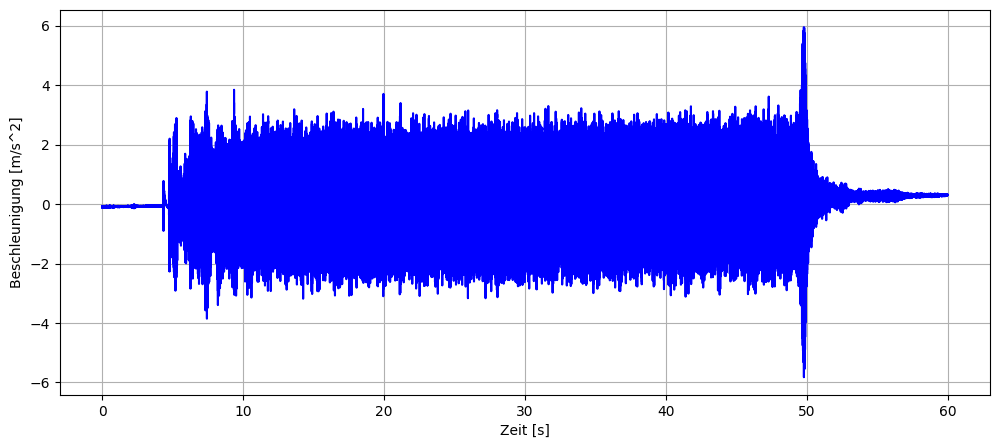

In [4]:
a = np.loadtxt('data/Pump_Vibrations.txt', skiprows=2) * 9.81  # Beschleunigungssignal [g] = 9.81 m/s^2
fs = 5120  # Abtastfrequenz (siehe Kopfzeile) [Hz]
dt = 1/fs  # Abtastintervall [s]
N = len(a)  # Sampleanzahl [-]

t = np.arange(N) * dt  # Zeitarray [s]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t, a, 'b')
ax.set_xlabel('Zeit [s]')
ax.set_ylabel('Beschleunigung [m/s^2]')
ax.grid()
plt.show()

### b) Bandpassfilterung

Laut Norm ist ein Frequenzbereich von 10 Hz bis 1000 Hz massgebend, d. h. die Vibrationen in diesem Bereich sind relevant für die Berechnung der Schwingstärke. Aus diesem Grund soll das Signal bandbassgefiltert werden, wobei als Filter ein *Butterworth-Filter*-Bandpassfilter 4. Ordnung verwendet werden soll.

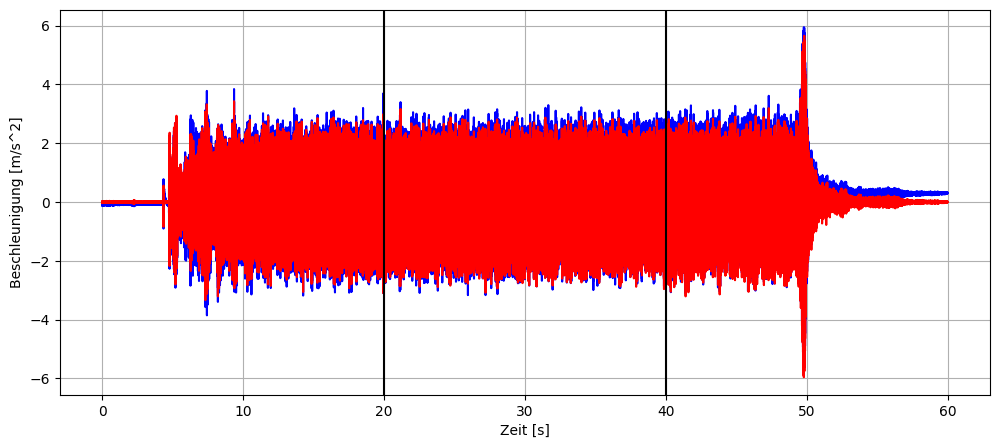

In [5]:
# Filterobjekt (Butterworth-Bandpassfilter)
filt = signal.butter(N = 4,  # Filterordnung
                     Wn = [10, 1000],  # Grenzfrequenzen 10, 1000 Hz
                     fs = fs,  # Abtastfrequenz
                     btype='band',  # Bandpassfilter ('low' für Tiefpass, 'high' für Hochpass)
                     output='sos')
                     
a_filt = signal.sosfiltfilt(filt, a)  # Filter auf Beschleunigungssignal anwenden

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t, a, 'b')
ax.plot(t, a_filt, 'r')
ax.axvline(20, color='k')
ax.axvline(40, color='k')
ax.set_xlabel('Zeit [s]')
ax.set_ylabel('Beschleunigung [m/s^2]')
ax.grid()
plt.show()

# Durch das Filtern werden tiefe Frequenzen unter 10 Hz (Gleichanteil, langsame Trends, ...) 
# und hohe Frequenzen über 1000 Hz (Rauschen, elektrische Störeinflüsse, ...) entfernt

### c) Berechnung der Schwinggeschwindigkeit

In der Norm ist die Schwinggeschwindigkeit massgebend, nicht die Schwingbeschleunigung. Wie du weisst, hängen Beschleunigung, Geschwindigkeit bzw. Position via Integration/Ableitung zusammen.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Zusammenhang_s_v_a.svg" width=80% />
</figure>

Für die numerische Integration mittels Trapezregel steht die Funktion `cumulative_trapezoid()` im Modul `integrate` von SciPy zur Verfügung.

- Die Berechnung soll nur innerhalb des "stationären" Bereichs erfolgen, d. h. das transiente Hoch- bzw. Runterfahren der Pumpe soll nicht berücksichtigt werden.

In [6]:
ausschnitt = (t > 20) & (t < 40)  # Vibrationen sollen nur im "stationären" Betrieb betrachtet werden

# Numerische Integration (mittels Trapezregel) des Beschleunigungssignals führt zur Schwinggeschwindigkeit [m/s]
v = integrate.cumulative_trapezoid(a_filt[ausschnitt],
                                   t[ausschnitt])

### d) Effektivwert der Schwinggeschwindigkeit

Um den energetisch äquivalenten Mittelwert einer Schwingung zu beschreiben, wird üblicherweise der Effektivwert (RMS-Wert) verwendet.

$$
v_{\text{RMS}} = \sqrt{\frac{1}{N} \sum_i{v_i^2}}
$$

- Da der Gleichanteil bei Schwingungsmessungen in der Regel keine Bedeutung hat (und das Ergebnis nur unnötig verfälschen kann), soll dieser vor der RMS-Bildung entfernt werden.

In [7]:
v = v - v.mean()  # Gleichanteil (Offset) wird entfernt, da nur Schwingungsanteil (AC) relevant ist

v_RMS = np.sqrt(np.mean(np.square(v))) * 1000  # RMS-Wert bestimmen und in [mm/s] umrechnen
print(f'Schwinggeschwindigkeit v_RMS = {v_RMS:.2f} mm/s')

Schwinggeschwindigkeit v_RMS = 2.41 mm/s


Da der Gleichanteil keine Rolle spielt und entfernt wurde, hätte man alternativ direkt die Standardabweichung bestimmen können `v.std()` (bei der Standardabweichung wird der Gleichanteil nicht berücksichtigt, d. h. dort hätte er nicht extra entfernt werden müssen).

$$ v_\sigma = \sqrt{\frac{1}{N} \sum_{i} \left( v_i-\bar{v} \right)^2}  $$

In [10]:
print(v.std() * 1000) 

2.4096568536101
